<a href="https://colab.research.google.com/github/githinjialicia/Kenya-linac-failure-prediction/blob/main/Week4_Statistics_and_Model_Idea.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment | Basic Statistics and the Input → Model → Output Idea
**Project:** Predicting medical equipment failure (radiotherapy LINAC) at Kenyatta National Hospital

In this notebook I used the same dataset from Week 3 (AI4I 2020 Predictive Maintenance Dataset). I picked a few numerical variables, calculated some basic statistics, look at how two of them are related, and showed the "input → model → output" idea.

## Step 0: Load the dataset again

In [1]:
# Install the helper package and import the tools we need
!pip install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# Download the dataset (same one as Week 3) and keep the full table
dataset = fetch_ucirepo(id=601)
df = dataset.data.original

# Show the first 5 rows to check that it loaded
df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 1: Choose 2 to 4 numerical variables

I chose four variables. They are the kind of machine readings that could also be recorded from a LINAC:
- **Air temperature** (in Kelvin)
- **Process temperature** (in Kelvin)
- **Rotational speed** (in rpm, how fast the machine part turns)
- **Torque** (in Nm, how much turning force the machine is working with)

In [2]:
# A small helper that finds a column by part of its name
# (so the code still works if the column names are written slightly differently)
def find_col(word):
    return [c for c in df.columns if word.lower() in c.lower()][0]

air_temp   = find_col("air temp")
proc_temp  = find_col("process temp")
speed      = find_col("rotational")
torque     = find_col("torque")

# Keep only the four columns we want to study
data = df[[air_temp, proc_temp, speed, torque]]
data.head()

,Air temperature,Process temperature,Rotational speed,Torque
0,298.1,308.6,1551,42.8
1,298.2,308.7,1408,46.3
2,298.1,308.5,1498,49.4
3,298.2,308.6,1433,39.5
4,298.2,308.7,1408,40.0


## Step 2: Mean, median, range, variance and standard deviation

- **Mean** = the average value
- **Median** = the middle value when everything is sorted
- **Range** = biggest value minus smallest value
- **Variance** and **standard deviation** = how spread out the values are (standard deviation is the square root of the variance)

In [3]:
# Calculate each statistic for every variable and put them in one table
stats = pd.DataFrame({
    "Mean": data.mean(),
    "Median": data.median(),
    "Range": data.max() - data.min(),
    "Variance": data.var(),
    "Standard deviation": data.std()
}).round(2)

stats

,Mean,Median,Range,Variance,Standard deviation
Air temperature,300.00,300.1,9.2,4.00,2.00
Process temperature,310.01,310.1,8.1,2.20,1.48
Rotational speed,1538.78,1503.0,1718.0,32142.79,179.28
Torque,39.99,40.1,72.8,99.38,9.97


## Step 3: Covariance and correlation between two variables

I chose **Rotational speed** and **Torque**. In a machine these two are linked, because the same motor power can either spin fast with a light load or spin slowly with a heavy load.

- **Covariance** tells us whether two variables tend to go up and down together (positive) or in opposite directions (negative).
- **Correlation** does the same job but on a fixed scale from -1 to +1, so it is easier to read.

In [4]:
# Covariance between rotational speed and torque
cov_value = data[speed].cov(data[torque])

# Correlation between rotational speed and torque
corr_value = data[speed].corr(data[torque])

print("Covariance:", round(cov_value, 2))
print("Correlation:", round(corr_value, 3))

Covariance: -1563.91
Correlation: -0.875


## Step 4: A simple plot of the two variables

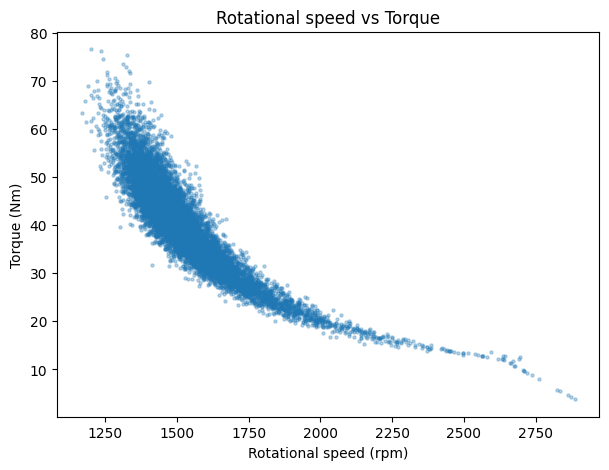

In [5]:
# Scatter plot: each dot is one machine reading
plt.figure(figsize=(7, 5))
plt.scatter(data[speed], data[torque], s=5, alpha=0.3)
plt.xlabel("Rotational speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.title("Rotational speed vs Torque")
plt.show()

##Results


The table shows the typical value of each variable (mean and median) and how much it varies (range, variance and standard deviation). The mean and median of each variable are fairly close, which means the readings are mostly balanced around a typical value. For rotational speed the mean is a little higher than the median, which suggests a few high-speed readings pull the average up. The temperatures vary only a little (a standard deviation of a few Kelvin), while rotational speed and torque vary much more. I cannot compare the variances directly, because each variable is measured in different units.

**Correlation**
The correlation between rotational speed and torque is strongly **negative** (close to -0.9). This means that when rotational speed goes up, torque tends to go down, and the other way round. The scatter plot shows the same thing: the dots slope downward from left to right.

**Does correlation mean that one variable causes the other?**
No. Correlation only shows that two variables move together. It does not prove that one causes the other. In this case the link probably comes from how the machine is designed (the same power is shared between speed and torque), not because speed on its own makes torque change. Two variables can also move together because of a third factor that we have not measured. For my LINAC project this matters: if a reading is correlated with failure, it is a useful warning sign, but it does not prove that the reading caused the failure.

## Input → Function/Model → Output

The idea behind machine learning is:

**Input (x)  →  Function / Model f  →  Output (y)**

For this example I choose:
- **Input (x):** Rotational speed
- **Output (y):** Torque

The simple mathematical expression is:

**y = f(x) = a·x + b**

Here *a* is the slope (how much torque changes when speed goes up by 1 rpm) and *b* is the starting value. The model "learns" a and b by finding the straight line that fits the dots best.

In my real project, the inputs would be the LINAC readings (temperatures, power, hours of use) and the output would be the chance that the machine fails soon.

Torque = -0.0487 x Speed + 114.86
If the speed is 1500 rpm, the model predicts a torque of about 41.9 Nm


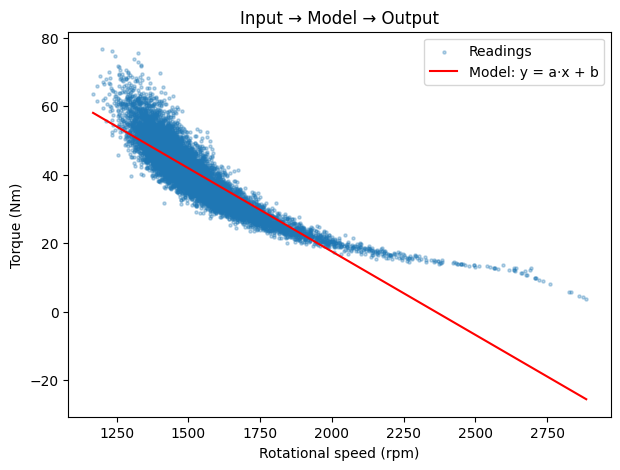

In [6]:
# Find the best-fitting straight line: torque = a * speed + b
a, b = np.polyfit(data[speed], data[torque], 1)

print(f"Torque = {a:.4f} x Speed + {b:.2f}")

# Use the line as a simple model: input a speed, get a predicted torque
def predict_torque(speed_value):
    return a * speed_value + b

example_speed = 1500
print(f"If the speed is {example_speed} rpm, the model predicts a torque of about {predict_torque(example_speed):.1f} Nm")

# Plot the dots again, with the fitted line on top
plt.figure(figsize=(7, 5))
plt.scatter(data[speed], data[torque], s=5, alpha=0.3, label="Readings")
xs = np.linspace(data[speed].min(), data[speed].max(), 100)
plt.plot(xs, predict_torque(xs), color="red", label="Model: y = a·x + b")
plt.xlabel("Rotational speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.title("Input → Model → Output")
plt.legend()
plt.show()

## Short summary

I picked four machine readings, calculated their basic statistics, and found that rotational speed and torque are strongly negatively correlated. I then showed the input → model → output idea with a straight line that predicts torque from speed. The same idea, with more inputs and a failure label as the output, is what I would use to predict LINAC breakdowns.